In [1]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt

# Thiết lập để import từ thư mục src
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from src.features import lexical_features
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [2]:
PROCESSED_DATA_PATH = 'data/processed/dataset_processed.csv'
df = pd.read_csv(PROCESSED_DATA_PATH)

In [3]:
print("Bắt đầu trích xuất bộ đặc trưng văn bản đầy đủ...")

# Danh sách các hàm cần áp dụng
feature_functions = {
    'url_length': lexical_features.get_url_length,
    'hostname_length': lexical_features.get_hostname_length,
    'dot_count': lexical_features.count_dots,
    'hyphen_count': lexical_features.count_hyphens,
    'at_symbol_count': lexical_features.count_at_symbol,
    'slash_count': lexical_features.count_slashes,
    'question_mark_count': lexical_features.count_question_mark,
    'equals_count': lexical_features.count_equals,
    'and_symbol_count': lexical_features.count_and_symbol,
    'path_length': lexical_features.get_path_length,
    'url_digit_count': lexical_features.count_digits_in_url,
    'url_letter_count': lexical_features.count_letters_in_url,
    'hostname_digit_count': lexical_features.count_digits_in_hostname,
    'has_https': lexical_features.has_https,
    'has_suspicious_tld': lexical_features.has_suspicious_tld,
}

# Áp dụng tất cả các hàm một cách tự động
for feature_name, func in feature_functions.items():
    print(f"  - Trích xuất '{feature_name}'...")
    df[feature_name] = df['url'].apply(func)

print("\nTrích xuất đặc trưng hoàn tất!")
print("\n5 dòng đầu tiên với các đặc trưng mới:")
print(df.head())

Bắt đầu trích xuất bộ đặc trưng văn bản đầy đủ...
  - Trích xuất 'url_length'...
  - Trích xuất 'hostname_length'...
  - Trích xuất 'dot_count'...
  - Trích xuất 'hyphen_count'...
  - Trích xuất 'at_symbol_count'...
  - Trích xuất 'slash_count'...
  - Trích xuất 'question_mark_count'...
  - Trích xuất 'equals_count'...
  - Trích xuất 'and_symbol_count'...
  - Trích xuất 'path_length'...
  - Trích xuất 'url_digit_count'...
  - Trích xuất 'url_letter_count'...
  - Trích xuất 'hostname_digit_count'...
  - Trích xuất 'has_https'...
  - Trích xuất 'has_suspicious_tld'...

Trích xuất đặc trưng hoàn tất!

5 dòng đầu tiên với các đặc trưng mới:
                                                 url  label  url_length  \
0                    tr7.datahost84.org/rrca.php?id=      1          31   
1                           samyinayeh.com/login.htm      1          24   
2  paypal.us.cgi.bin.webscr.cmd.login.webapps.mpp...      1         142   
3  phoenixafrica.biz/wp-content/themes/twentyelev...   

In [4]:
# Cập nhật danh sách các cột đặc trưng
feature_columns = list(feature_functions.keys())

X = df[feature_columns]
y = df['label']

print("Kích thước ma trận đặc trưng X:", X.shape)
print("\nCác đặc trưng được sử dụng:")
print(X.columns.tolist())

Kích thước ma trận đặc trưng X: (507195, 15)

Các đặc trưng được sử dụng:
['url_length', 'hostname_length', 'dot_count', 'hyphen_count', 'at_symbol_count', 'slash_count', 'question_mark_count', 'equals_count', 'and_symbol_count', 'path_length', 'url_digit_count', 'url_letter_count', 'hostname_digit_count', 'has_https', 'has_suspicious_tld']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- Mô hình 1: Logistic Regression ---
print("Bắt đầu huấn luyện mô hình Logistic Regression...")
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train, y_train)
print("Huấn luyện Logistic Regression hoàn tất!")

# --- Mô hình 2: Random Forest ---
print("\nBắt đầu huấn luyện mô hình Random Forest...")

# n_jobs = -1: Sử dụng tất cả các nhân CPU để huấn luyện nhanh hơn
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train, y_train)
print("Huấn luyện Random Forest hoàn tất!")


Bắt đầu huấn luyện mô hình Logistic Regression...
Huấn luyện Logistic Regression hoàn tất!

Bắt đầu huấn luyện mô hình Random Forest...
Huấn luyện Random Forest hoàn tất!


--- Đánh giá mô hình Logistic Regression ---
              precision    recall  f1-score   support

  Legitimate       0.84      0.97      0.90     78579
    Phishing       0.80      0.35      0.49     22860

    accuracy                           0.83    101439
   macro avg       0.82      0.66      0.70    101439
weighted avg       0.83      0.83      0.81    101439



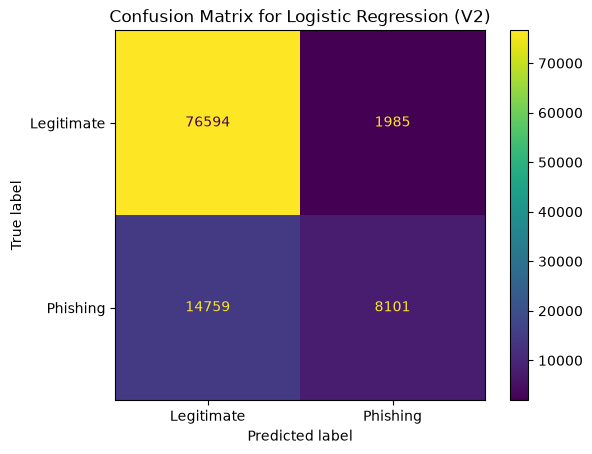



--- Đánh giá mô hình Random Forest ---
              precision    recall  f1-score   support

  Legitimate       0.92      0.96      0.94     78579
    Phishing       0.84      0.71      0.77     22860

    accuracy                           0.90    101439
   macro avg       0.88      0.84      0.86    101439
weighted avg       0.90      0.90      0.90    101439



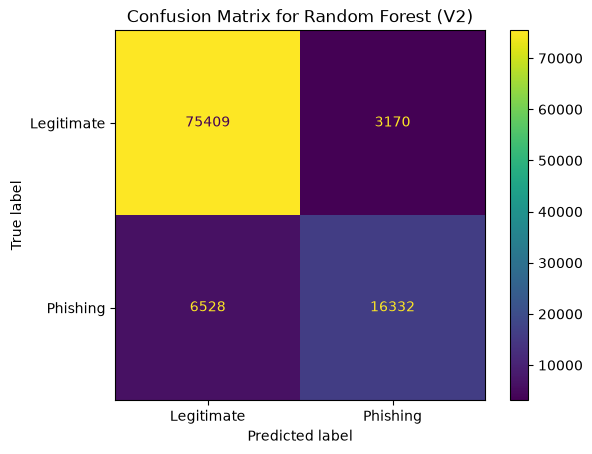

In [7]:
print("--- Đánh giá mô hình Logistic Regression ---")
y_pred_lr = model_lr.predict(X_test)
print(classification_report(y_test, y_pred_lr, target_names=['Legitimate', 'Phishing']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=['Legitimate', 'Phishing'])
plt.title("Confusion Matrix for Logistic Regression (V2)")
plt.show()

print("\n" + "="*50 + "\n")

print("--- Đánh giá mô hình Random Forest ---")
y_pred_rf = model_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=['Legitimate', 'Phishing']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=['Legitimate', 'Phishing'])
plt.title("Confusion Matrix for Random Forest (V2)")
plt.show()